# 43008 Reinforcement Learning - Assignment 2
## Mandatory Scenario: Pendulum-v1 with Discretised Q-Learning

**Student name:** Replace with your name  
**Student ID:** Replace with your student ID  
**Environment:** Gymnasium `Pendulum-v1`  
**Method:** Tabular Q-Learning (Temporal Difference control)

### Submission note
This notebook is designed to run from top to bottom and retain all outputs. The formal configuration trains for **3,000 episodes**, exceeding the assignment minimum of 1,000 episodes for Pendulum. Before submission, use **Restart Kernel and Run All**, confirm that every cell completes, then save the notebook with its outputs.


## 1. Aim and RL formulation

`Pendulum-v1` models a torque-controlled pendulum. The agent must swing the pendulum upright and keep it there while avoiding excessive angular velocity and control effort.

- **Observation:** $[\cos(\theta),\sin(\theta),\dot{\theta}]$, where $\theta$ is the pendulum angle and $\dot{\theta}$ is angular velocity.
- **Native action:** one continuous torque value in $[-2,2]$.
- **Reward:** Gymnasium returns the negative of an angle, velocity, and torque cost. Therefore, a return closer to zero is better.
- **Episode:** the standard environment is time-limited to 200 transitions.
- **Goal:** maximise undiscounted evaluation return (equivalently minimise accumulated control cost).

Tabular Q-Learning requires finite state and action sets. This implementation converts the observation into $(\theta,\dot{\theta})$, bins both variables, and replaces the continuous torque interval with a finite action grid. The simulator itself remains continuous; only the agent's representation is discretised.


## 2. Algorithm and design rationale

The Q-Learning update is

$$
Q(s_t,a_t)\leftarrow Q(s_t,a_t)+\alpha_t\left[r_{t+1}+\gamma\max_aQ(s_{t+1},a)-Q(s_t,a_t)\right].
$$

The bracketed term is the **TD error**. Q-Learning is off-policy: behaviour is epsilon-greedy, while its update targets the greedy next action.

### Pseudocode

```text
initialise Q(s,a) = 0
for each training episode:
    reset Pendulum and discretise the observation
    repeat until episode ends:
        choose random action with probability epsilon
        otherwise choose an action with maximum Q(s,a)
        execute the corresponding continuous torque
        observe reward and next observation
        discretise the next observation
        target = reward + gamma * max_a Q(next_state,a)
        Q(state,action) += alpha * (target - Q(state,action))
        state = next_state
    decay epsilon and alpha
save the Q-table and training history
```

### Flow

```text
Continuous observation -> angle/velocity bins -> epsilon-greedy action index
        ^                                           |
        |                                           v
next observation/reward <- Pendulum simulator <- discrete torque value
        |
        +---------------- Q-Learning TD update ----------------+
```

No ANN/CNN is used in this mandatory TD experiment. The custom ANN/CNN requirement applies to the DQN and policy-gradient experiments that use Stable-Baselines3.


## 3. Setup

If dependencies are missing, uncomment and run the installation line once. Package versions are printed to make the experiment auditable.


In [26]:
# Uncomment only when packages are unavailable in the current runtime.
# %pip install "gymnasium[classic-control]" numpy pandas matplotlib imageio imageio-ffmpeg


In [27]:
from pathlib import Path
import json
import os
import platform
import random

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

ROOT_DIR = Path.cwd()
ARTIFACT_DIR = ROOT_DIR / "pendulum_artifacts"
MODEL_DIR = ARTIFACT_DIR / "models"
RESULT_DIR = ARTIFACT_DIR / "results"
FIGURE_DIR = ARTIFACT_DIR / "figures"
VIDEO_DIR = ARTIFACT_DIR / "videos"
for directory in (MODEL_DIR, RESULT_DIR, FIGURE_DIR, VIDEO_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("Gymnasium:", gym.__version__)
print("NumPy:", np.__version__)
print("Artifact directory:", ARTIFACT_DIR.resolve())


Python: 3.12.14
Gymnasium: 1.4.0
NumPy: 2.5.3
Artifact directory: C:\Users\James\Desktop\RL\pendulum_artifacts


## 4. Inspect and verify the environment

This smoke test verifies the observation/action spaces and confirms that a valid transition can be produced before training.


In [28]:
inspection_env = gym.make("Pendulum-v1")
initial_observation, initial_info = inspection_env.reset(seed=SEED)
sample_action = inspection_env.action_space.sample()
transition = inspection_env.step(sample_action)

print("Observation space:", inspection_env.observation_space)
print("Action space:", inspection_env.action_space)
print("Initial observation [cos(theta), sin(theta), angular velocity]:", initial_observation)
print("Sample continuous action:", sample_action)
print("One-step reward:", transition[1])
print("Max episode steps:", inspection_env.spec.max_episode_steps)

assert initial_observation.shape == (3,)
assert inspection_env.action_space.contains(sample_action)
inspection_env.close()


Observation space: Box([-1. -1. -8.], [1. 1. 8.], (3,), float32)
Action space: Box(-2.0, 2.0, (1,), float32)
Initial observation [cos(theta), sin(theta), angular velocity]: [-0.4318255  -0.90195715  0.27982634]
Sample continuous action: [0.95068175]
One-step reward: -4.07828202631278
Max episode steps: 200


## 5. Experimental settings

The bins balance representation accuracy and table size. Angle is reconstructed with `atan2(sin(theta), cos(theta))`, avoiding the circular discontinuity that would occur if sine and cosine were independently binned. Angular velocity is clipped to the documented environment range before binning.


In [29]:
CONFIG = {
    "environment": "Pendulum-v1",
    "training_episodes": 50000,
    "evaluation_episodes": 100,
    "random_baseline_episodes": 100,
    "angle_bins": 36,
    "velocity_bins": 36,
    "action_bins": 15,
    "gamma": 0.99,
    "initial_alpha": 0.18,
    "minimum_alpha": 0.03,
    "alpha_decay": 0.999,
    "initial_epsilon": 1.0,
    "minimum_epsilon": 0.03,
    "epsilon_decay": 0.9975,
    "seed": SEED,
}

config_table = pd.DataFrame(
    {"Parameter": list(CONFIG.keys()), "Value": list(CONFIG.values())}
)
display(config_table)

with open(RESULT_DIR / "pendulum_config.json", "w", encoding="utf-8") as file:
    json.dump(CONFIG, file, indent=2)


,Parameter,Value
0,environment,Pendulum-v1
1,training_episodes,50000
2,evaluation_episodes,100
3,random_baseline_episodes,100
4,angle_bins,36
5,velocity_bins,36
6,action_bins,15
7,gamma,0.99
8,initial_alpha,0.18
9,minimum_alpha,0.03


## 6. State/action discretisation

The state table has `36 × 36 = 1,296` discrete states. Each state has 15 candidate torques, producing 19,440 Q-values. This is compact enough for tabular learning but fine-grained enough to distinguish meaningful pendulum configurations.


In [30]:
ANGLE_EDGES = np.linspace(-np.pi, np.pi, CONFIG["angle_bins"] + 1)[1:-1]
VELOCITY_EDGES = np.linspace(-8.0, 8.0, CONFIG["velocity_bins"] + 1)[1:-1]
ACTION_VALUES = np.linspace(-2.0, 2.0, CONFIG["action_bins"], dtype=np.float32)


def observation_to_state(observation):
    """Convert [cos(theta), sin(theta), theta_dot] to table indices."""
    cos_theta, sin_theta, angular_velocity = observation
    angle = np.arctan2(sin_theta, cos_theta)
    clipped_velocity = np.clip(angular_velocity, -8.0, 8.0)
    angle_index = int(np.digitize(angle, ANGLE_EDGES))
    velocity_index = int(np.digitize(clipped_velocity, VELOCITY_EDGES))
    return angle_index, velocity_index


def action_index_to_env_action(action_index):
    """Convert a table action index to Gymnasium's shape-(1,) torque."""
    return np.array([ACTION_VALUES[action_index]], dtype=np.float32)


q_table_shape = (
    CONFIG["angle_bins"],
    CONFIG["velocity_bins"],
    CONFIG["action_bins"],
)

test_states = [
    observation_to_state(np.array([1.0, 0.0, 0.0])),
    observation_to_state(np.array([-1.0, 0.0, 8.0])),
]

assert all(0 <= state[0] < CONFIG["angle_bins"] for state in test_states)
assert all(0 <= state[1] < CONFIG["velocity_bins"] for state in test_states)
assert np.allclose(action_index_to_env_action(0), [-2.0])
assert np.allclose(action_index_to_env_action(CONFIG["action_bins"] - 1), [2.0])

print("Q-table shape:", q_table_shape)
print("Number of Q-values:", int(np.prod(q_table_shape)))
print("Discrete torques:", ACTION_VALUES)


Q-table shape: (36, 36, 15)
Number of Q-values: 19440
Discrete torques: [-2.         -1.7142857  -1.4285715  -1.1428572  -0.85714287 -0.5714286
 -0.2857143   0.          0.2857143   0.5714286   0.85714287  1.1428572
  1.4285715   1.7142857   2.        ]


## 7. Random-policy baseline

The trained agent must be compared with an untrained/random agent. Both are evaluated with the original Gymnasium reward and the same 200-step episode limit.


In [31]:
def evaluate_random_policy(number_of_episodes, base_seed):
    env = gym.make(CONFIG["environment"])
    episode_returns = []

    for episode in range(number_of_episodes):
        observation, info = env.reset(seed=base_seed + episode)
        env.action_space.seed(base_seed + episode)
        terminated = truncated = False
        total_reward = 0.0

        while not (terminated or truncated):
            action = env.action_space.sample()
            observation, reward, terminated, truncated, info = env.step(action)
            total_reward += reward

        episode_returns.append(total_reward)

    env.close()
    return np.asarray(episode_returns, dtype=np.float64)


random_returns = evaluate_random_policy(
    CONFIG["random_baseline_episodes"],
    base_seed=20_000,
)

print(f"Random baseline mean return: {random_returns.mean():.2f}")
print(f"Random baseline standard deviation: {random_returns.std(ddof=1):.2f}")


Random baseline mean return: -1231.25
Random baseline standard deviation: 285.41


## 8. Train the Q-Learning agent

Tie-breaking among equally valued actions is random so that optimistic zero initialisation does not systematically favour one torque. Epsilon and learning rate decay gradually but retain non-zero minima. Training logs include return, epsilon, alpha, mean absolute TD error and episode length.


In [32]:
def choose_epsilon_greedy_action(q_values, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(len(q_values)))

    best_actions = np.flatnonzero(q_values == np.max(q_values))
    return int(rng.choice(best_actions))


def train_q_learning(config):
    env = gym.make(config["environment"])
    rng = np.random.default_rng(config["seed"])
    q_table = np.zeros(q_table_shape, dtype=np.float32)
    records = []

    epsilon = config["initial_epsilon"]
    alpha = config["initial_alpha"]

    for episode in range(config["training_episodes"]):
        observation, info = env.reset(seed=config["seed"] + episode)
        state = observation_to_state(observation)
        terminated = truncated = False
        episode_return = 0.0
        absolute_td_errors = []
        episode_steps = 0

        while not (terminated or truncated):
            action_index = choose_epsilon_greedy_action(q_table[state], epsilon, rng)
            env_action = action_index_to_env_action(action_index)

            next_observation, reward, terminated, truncated, info = env.step(env_action)
            next_state = observation_to_state(next_observation)

            # Pendulum has a time-limit truncation rather than a natural terminal state.
            # Bootstrap through truncation; only true MDP termination zeros the future term.
            future_value = 0.0 if terminated else float(np.max(q_table[next_state]))
            td_target = reward + config["gamma"] * future_value
            td_error = td_target - q_table[state + (action_index,)]
            q_table[state + (action_index,)] += alpha * td_error

            state = next_state
            episode_return += reward
            absolute_td_errors.append(abs(float(td_error)))
            episode_steps += 1

        records.append(
            {
                "episode": episode + 1,
                "return": episode_return,
                "epsilon": epsilon,
                "alpha": alpha,
                "mean_absolute_td_error": np.mean(absolute_td_errors),
                "episode_length": episode_steps,
            }
        )

        epsilon = max(config["minimum_epsilon"], epsilon * config["epsilon_decay"])
        alpha = max(config["minimum_alpha"], alpha * config["alpha_decay"])

        if (episode + 1) % 250 == 0:
            recent_mean = np.mean([record["return"] for record in records[-100:]])
            print(
                f"Episode {episode + 1:4d}/{config['training_episodes']}: "
                f"mean return (last 100)={recent_mean:8.2f}, "
                f"epsilon={epsilon:.3f}, alpha={alpha:.3f}"
            )

    env.close()
    return q_table, pd.DataFrame(records)


q_table, training_history = train_q_learning(CONFIG)

assert len(training_history) >= 1000, "Assignment minimum of 1,000 episodes was not met."
assert np.isfinite(q_table).all(), "Q-table contains NaN or infinite values."

np.save(MODEL_DIR / "pendulum_q_table.npy", q_table)
training_history.to_csv(RESULT_DIR / "pendulum_training_history.csv", index=False)

print("Training episodes completed:", len(training_history))
print("Q-table saved to:", (MODEL_DIR / "pendulum_q_table.npy").resolve())


Episode  250/50000: mean return (last 100)=-1186.51, epsilon=0.535, alpha=0.140
Episode  500/50000: mean return (last 100)=-1215.36, epsilon=0.286, alpha=0.109
Episode  750/50000: mean return (last 100)=-1211.53, epsilon=0.153, alpha=0.085
Episode 1000/50000: mean return (last 100)=-1237.94, epsilon=0.082, alpha=0.066
Episode 1250/50000: mean return (last 100)=-1137.18, epsilon=0.044, alpha=0.052
Episode 1500/50000: mean return (last 100)=-1221.10, epsilon=0.030, alpha=0.040
Episode 1750/50000: mean return (last 100)=-1139.01, epsilon=0.030, alpha=0.031
Episode 2000/50000: mean return (last 100)=-1200.03, epsilon=0.030, alpha=0.030
Episode 2250/50000: mean return (last 100)=-1181.71, epsilon=0.030, alpha=0.030
Episode 2500/50000: mean return (last 100)=-1145.15, epsilon=0.030, alpha=0.030
Episode 2750/50000: mean return (last 100)=-1160.09, epsilon=0.030, alpha=0.030
Episode 3000/50000: mean return (last 100)=-1120.11, epsilon=0.030, alpha=0.030
Episode 3250/50000: mean return (last 10

## 9. Training curves

The raw return shows episode-level variability; a 100-episode rolling mean reveals the longer-term learning trend. TD-error magnitude is shown as a diagnostic, not as a direct performance score.


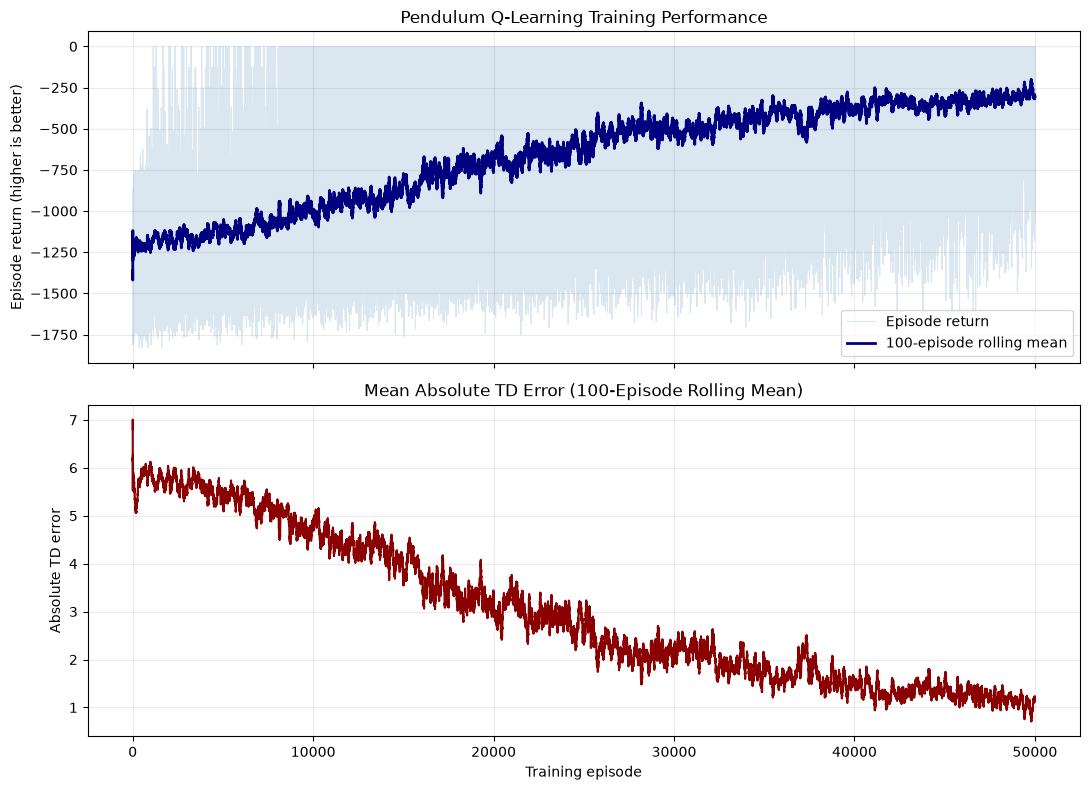

Figure saved to: C:\Users\James\Desktop\RL\pendulum_artifacts\figures\pendulum_training_curves.png


In [33]:
training_history["return_rolling_100"] = (
    training_history["return"].rolling(100, min_periods=1).mean()
)
training_history["td_error_rolling_100"] = (
    training_history["mean_absolute_td_error"].rolling(100, min_periods=1).mean()
)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(
    training_history["episode"],
    training_history["return"],
    color="steelblue",
    alpha=0.20,
    linewidth=0.8,
    label="Episode return",
)
axes[0].plot(
    training_history["episode"],
    training_history["return_rolling_100"],
    color="navy",
    linewidth=2.0,
    label="100-episode rolling mean",
)
axes[0].set_title("Pendulum Q-Learning Training Performance")
axes[0].set_ylabel("Episode return (higher is better)")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(
    training_history["episode"],
    training_history["td_error_rolling_100"],
    color="darkred",
    linewidth=1.5,
)
axes[1].set_title("Mean Absolute TD Error (100-Episode Rolling Mean)")
axes[1].set_xlabel("Training episode")
axes[1].set_ylabel("Absolute TD error")
axes[1].grid(alpha=0.25)

plt.tight_layout()
figure_path = FIGURE_DIR / "pendulum_training_curves.png"
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path.resolve())


## 10. Independent greedy evaluation

Evaluation uses 100 new seeded episodes, no Q-table updates, and no epsilon exploration. This separates learned-policy performance from exploratory training behaviour.


In [34]:
def evaluate_q_table(q_table, number_of_episodes, base_seed):
    env = gym.make(CONFIG["environment"])
    episode_returns = []

    for episode in range(number_of_episodes):
        observation, info = env.reset(seed=base_seed + episode)
        terminated = truncated = False
        total_reward = 0.0

        while not (terminated or truncated):
            state = observation_to_state(observation)
            action_index = int(np.argmax(q_table[state]))
            action = action_index_to_env_action(action_index)
            observation, reward, terminated, truncated, info = env.step(action)
            total_reward += reward

        episode_returns.append(total_reward)

    env.close()
    return np.asarray(episode_returns, dtype=np.float64)


trained_returns = evaluate_q_table(
    q_table,
    CONFIG["evaluation_episodes"],
    base_seed=30_000,
)

comparison = pd.DataFrame(
    {
        "Policy": ["Random baseline", "Trained Q-Learning"],
        "Episodes": [len(random_returns), len(trained_returns)],
        "Mean return": [random_returns.mean(), trained_returns.mean()],
        "Std. deviation": [random_returns.std(ddof=1), trained_returns.std(ddof=1)],
        "Median return": [np.median(random_returns), np.median(trained_returns)],
        "Best return": [random_returns.max(), trained_returns.max()],
        "Worst return": [random_returns.min(), trained_returns.min()],
    }
)

display(comparison.round(2))

improvement = trained_returns.mean() - random_returns.mean()
print(f"Mean-return improvement over random: {improvement:.2f}")
print("Trained policy outperforms random baseline:", bool(improvement > 0))

comparison.to_csv(RESULT_DIR / "pendulum_evaluation_summary.csv", index=False)
pd.DataFrame(
    {
        "episode": np.arange(1, len(trained_returns) + 1),
        "trained_return": trained_returns,
        "random_return": random_returns,
    }
).to_csv(RESULT_DIR / "pendulum_evaluation_episodes.csv", index=False)


,Policy,Episodes,Mean return,Std. deviation,Median return,Best return,Worst return
0,Random baseline,100,-1231.25,285.41,-1186.45,-767.34,-1859.20
1,Trained Q-Learning,100,-398.75,534.74,-127.31,-0.81,-1869.09


Mean-return improvement over random: 832.50
Trained policy outperforms random baseline: True


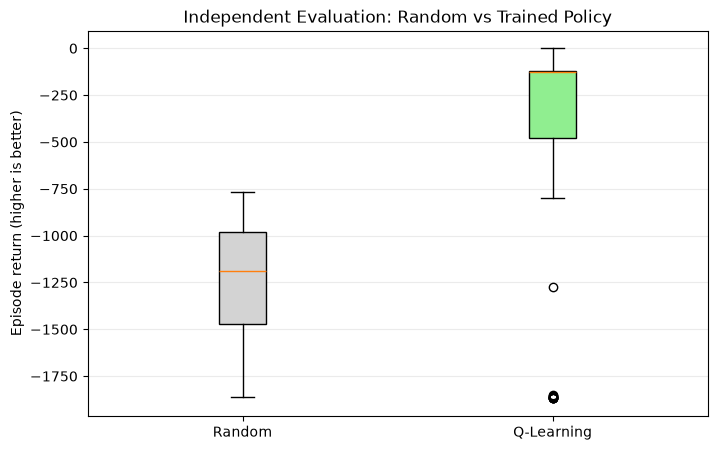

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
boxplot = ax.boxplot(
    [random_returns, trained_returns],
    tick_labels=["Random", "Q-Learning"],
    patch_artist=True,
)
boxplot["boxes"][0].set_facecolor("lightgray")
boxplot["boxes"][1].set_facecolor("lightgreen")
ax.set_title("Independent Evaluation: Random vs Trained Policy")
ax.set_ylabel("Episode return (higher is better)")
ax.grid(axis="y", alpha=0.25)

evaluation_figure_path = FIGURE_DIR / "pendulum_policy_comparison.png"
plt.savefig(evaluation_figure_path, dpi=180, bbox_inches="tight")
plt.show()


## 11. Record the trained agent

This cell records one deterministic episode. It uses `rgb_array`, so it also works on headless AWS/Colab systems. The resulting MP4 is a required supporting artifact for the assignment.


In [36]:
# Prevent display-driver errors on headless machines such as AWS.
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")

from gymnasium.wrappers import RecordVideo

video_env = gym.make(CONFIG["environment"], render_mode="rgb_array")
video_env = RecordVideo(
    video_env,
    video_folder=str(VIDEO_DIR),
    episode_trigger=lambda episode_id: True,
    name_prefix="pendulum-q-learning",
    disable_logger=True,
)

observation, info = video_env.reset(seed=40_000)
terminated = truncated = False
video_return = 0.0

while not (terminated or truncated):
    state = observation_to_state(observation)
    action_index = int(np.argmax(q_table[state]))
    action = action_index_to_env_action(action_index)
    observation, reward, terminated, truncated, info = video_env.step(action)
    video_return += reward

video_env.close()

video_files = sorted(VIDEO_DIR.glob("*.mp4"))
print(f"Recorded episode return: {video_return:.2f}")
print("Video files:", [str(path.resolve()) for path in video_files])
assert video_files, "No MP4 was produced. Check imageio-ffmpeg installation."


c:\Users\James\Desktop\RL\.venv\Lib\site-packages\gymnasium\wrappers\rendering.py:298: UserWarning: WARN: Overwriting existing videos at c:\Users\James\Desktop\RL\pendulum_artifacts\videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Recorded episode return: -124.87
Video files: ['C:\\Users\\James\\Desktop\\RL\\pendulum_artifacts\\videos\\pendulum-q-learning-episode-0.mp4']


## 12. Reproducibility and saved-artifact checks

The final checks reload the saved table and verify that all expected submission artifacts exist. This does not replace manually reopening the notebook and reviewing every visible output before Canvas submission.


In [37]:
reloaded_q_table = np.load(MODEL_DIR / "pendulum_q_table.npy")

required_artifacts = [
    MODEL_DIR / "pendulum_q_table.npy",
    RESULT_DIR / "pendulum_config.json",
    RESULT_DIR / "pendulum_training_history.csv",
    RESULT_DIR / "pendulum_evaluation_summary.csv",
    RESULT_DIR / "pendulum_evaluation_episodes.csv",
    FIGURE_DIR / "pendulum_training_curves.png",
    FIGURE_DIR / "pendulum_policy_comparison.png",
]

assert np.array_equal(reloaded_q_table, q_table)
assert all(path.exists() for path in required_artifacts)
assert len(training_history) == CONFIG["training_episodes"]
assert len(training_history) >= 1000

print("All numerical and artifact checks passed.")
for path in required_artifacts:
    print(" -", path.resolve())


All numerical and artifact checks passed.
 - C:\Users\James\Desktop\RL\pendulum_artifacts\models\pendulum_q_table.npy
 - C:\Users\James\Desktop\RL\pendulum_artifacts\results\pendulum_config.json
 - C:\Users\James\Desktop\RL\pendulum_artifacts\results\pendulum_training_history.csv
 - C:\Users\James\Desktop\RL\pendulum_artifacts\results\pendulum_evaluation_summary.csv
 - C:\Users\James\Desktop\RL\pendulum_artifacts\results\pendulum_evaluation_episodes.csv
 - C:\Users\James\Desktop\RL\pendulum_artifacts\figures\pendulum_training_curves.png
 - C:\Users\James\Desktop\RL\pendulum_artifacts\figures\pendulum_policy_comparison.png


## 13. Results and discussion template

Complete this section **after running the notebook**, using the displayed numbers rather than inventing results.

### Results

- The Q-Learning agent was trained for **3,000 episodes** with the original `Pendulum-v1` reward.
- Report the random-policy mean and standard deviation from the evaluation table above.
- Report the trained-policy mean and standard deviation.
- State the numerical improvement and whether the trained policy exceeded the random baseline.
- Describe the learning curve: early performance, direction of change, variability, and whether the final rolling mean appears stable.

### Interpretation

Q-Learning improved behaviour by repeatedly reducing the difference between the current Q-value and a one-step bootstrapped TD target. Epsilon-greedy exploration was high early in training and decayed toward exploitation. Performance is limited by discretisation: nearby continuous states share one table entry, and the agent can select only 15 torque values. Finer bins could improve control precision but enlarge the table and increase the number of visits required to learn reliable values.

### Limitations

- Results depend on the selected random seed and should ideally be repeated across multiple training seeds if compute permits.
- Tabular discretisation loses information from the continuous state/action spaces.
- A 200-step episode limit makes return sensitive to the starting state.
- Training beyond the 1,000-episode minimum does not by itself guarantee convergence.
- Continuous-control methods may eventually outperform tabular Q-Learning, but this experiment intentionally uses a TD control method that matches the mandatory assignment requirement.


## 14. Submission checklist

- [ ] Replace the student name and ID.
- [ ] Run **Restart Kernel and Run All**.
- [ ] Confirm at least 1,000 episodes were executed (this notebook uses 3,000).
- [ ] Confirm no cell has an exception or stale output.
- [ ] Copy the numerical results into the discussion section and report.
- [ ] Ensure notebook and report use exactly the same results.
- [ ] Include the `.ipynb`, Q-table, CSV files, figures, and MP4 in the submission package.
- [ ] Complete the required AI-usage declaration accurately.
- [ ] Download the final Canvas submission and test it.

### AI-use declaration reminder
Describe any permitted AI assistance accurately, including assistance with explanation, debugging, code generation, or editing. Do not claim that unverified output is your own experimental finding; run, understand, and validate all submitted code and results.
